<a href="https://colab.research.google.com/github/Bbangguu/hello-world/blob/main/Yolov8n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
%pip install -q "requests==2.32.4" fsspec tifffile matplotlib

In [29]:
import requests

api_url = "https://zenodo.org/api/records/5681008"

record = requests.get(api_url, timeout=60).json()

files = record["files"]

if isinstance(files, dict):
    files = list(files["entries"].values())

full_file = next(
    f for f in files
    if f["key"] == "XrayObjectDetectionDataset.zip"
)

url = (
    full_file["links"].get("content")
    or full_file["links"].get("self")
)

assert url, "다운로드 링크를 찾지 못했습니다."

# 파일 전체가 아니라 1바이트만 요청
response = requests.get(
    url,
    headers={
        "Range": "bytes=0-0",
        "Accept-Encoding": "identity"
    },
    stream=True,
    timeout=60
)

print("HTTP 상태 코드:", response.status_code)
print("Content-Range:", response.headers.get("Content-Range"))
print("Accept-Ranges:", response.headers.get("Accept-Ranges"))

range_supported = (
    response.status_code == 206
    and response.headers.get("Content-Range", "").startswith("bytes 0-0/")
)

response.close()

print("부분 다운로드 가능:", range_supported)

if not range_supported:
    print("이 서버에서는 부분 ZIP 접근을 확인하지 못했습니다.")

HTTP 상태 코드: 206
Content-Range: bytes 0-0/14579040916
Accept-Ranges: bytes
부분 다운로드 가능: True


In [30]:
import fsspec
import zipfile
from collections import Counter
from pathlib import Path

assert range_supported, "부분 다운로드가 지원되지 않습니다."

fs = fsspec.filesystem(
    "http",
    block_size=2 * 1024 * 1024
)

with fs.open(url, "rb") as remote_file:
    with zipfile.ZipFile(remote_file) as z:

        names = [
            n for n in z.namelist()
            if not n.endswith("/")
        ]

print("전체 파일 수:", len(names))

print("\n===== ZIP 내부 파일 예시 =====")
for n in names[:80]:
    print(n)

print("\n===== 상위 폴더별 파일 수 =====")
counts = Counter(
    "/".join(Path(n).parts[:2])
    for n in names
)

for folder, count in counts.most_common(30):
    print(folder, count)

전체 파일 수: 471600

===== ZIP 내부 파일 예시 =====
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0001.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0002.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0005.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0006.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0010.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0011.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0014.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0015.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0016.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0018.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0020.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0024.tiff
FewStonesInPlayDoh_GTProjectionsSmall/Instance

In [42]:
from collections import Counter
from pathlib import PurePosixPath

# STEP 3에서 생성한 names 사용
top_folders = Counter(
    PurePosixPath(n).parts[0]
    for n in names
)

print("===== 최상위 폴더 =====")

for folder, count in top_folders.items():
    print(folder, ":", count)

===== 최상위 폴더 =====
FewStonesInPlayDoh_GTProjectionsSmall : 199800
FewStonesInPlayDoh_XrayProjectionsCorrectedSmall : 199800
ManyStonesInPlayDoh_GTProjectionsSmall : 36000
ManyStonesInPlayDoh_XrayProjectionsCorrectedSmall : 36000


In [43]:
from collections import defaultdict
import random
import re

random.seed(42)

RAW_FOLDER = "FewStonesInPlayDoh_XrayProjectionsCorrectedSmall"
GT_FOLDER = "FewStonesInPlayDoh_GTProjectionsSmall"

# 파일명에서 Instance 번호와 Angle 번호 추출
def get_image_key(path):
    match = re.search(
        r"Instance(\d+).*?Angle(\d+)",
        path,
        re.IGNORECASE
    )

    if match:
        return (
            int(match.group(1)),
            int(match.group(2))
        )

    return None

raw_map = {}
gt_map = {}

for name in names:

    key = get_image_key(name)

    if key is None:
        continue

    if name.startswith(RAW_FOLDER + "/"):
        raw_map[key] = name

    elif name.startswith(GT_FOLDER + "/"):
        gt_map[key] = name

# 원본 X-ray와 Ground Truth 매칭
common_keys = sorted(set(raw_map) & set(gt_map))

print("원본 이미지:", len(raw_map))
print("GT 이미지:", len(gt_map))
print("매칭된 이미지 쌍:", len(common_keys))

assert common_keys, "원본과 GT가 매칭되지 않았습니다."

# Instance별 이미지 분류
by_instance = defaultdict(list)

for key in common_keys:
    instance_id, angle_id = key
    by_instance[instance_id].append(key)

# 서로 다른 점토 샘플 10개 선택
instances = sorted(by_instance.keys())[:10]

selected_pairs = []

for instance in instances:

    candidates = by_instance[instance]

    selected = random.sample(
        candidates,
        min(20, len(candidates))
    )

    for key in selected:
        selected_pairs.append(
            (raw_map[key], gt_map[key])
        )

print("\n선택한 Instance:", instances)
print("선택한 X-ray/GT 쌍:", len(selected_pairs))

print("\n매칭 예시:")
for raw, gt in selected_pairs[:3]:
    print("X-ray:", raw)
    print("GT:   ", gt)
    print()

원본 이미지: 199800
GT 이미지: 199800
매칭된 이미지 쌍: 199800

선택한 Instance: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
선택한 X-ray/GT 쌍: 200

매칭 예시:
X-ray: FewStonesInPlayDoh_XrayProjectionsCorrectedSmall/Instance001/Instance001Angle01309Data.tiff
GT:    FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle1309.tiff

X-ray: FewStonesInPlayDoh_XrayProjectionsCorrectedSmall/Instance001/Instance001Angle00228Data.tiff
GT:    FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0228.tiff

X-ray: FewStonesInPlayDoh_XrayProjectionsCorrectedSmall/Instance001/Instance001Angle00051Data.tiff
GT:    FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle0051.tiff



In [44]:
import fsspec #6
import zipfile
import shutil
from pathlib import Path

SAVE_DIR = Path("/content/ClayXray/subset")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

selected_files = set()

for raw, gt in selected_pairs:
    selected_files.add(raw)
    selected_files.add(gt)

print("추출 대상 파일:", len(selected_files))

with fs.open(url, "rb") as remote_file:
    with zipfile.ZipFile(remote_file) as z:

        total_size = sum(
            z.getinfo(n).file_size
            for n in selected_files
        )

        print(
            "압축 해제 예상 크기(MB):",
            round(total_size / 1024**2, 2)
        )

        assert total_size < 1024**3, (
            "선택 파일이 1GB를 초과했습니다."
        )

        for i, name in enumerate(sorted(selected_files), 1):

            destination = (SAVE_DIR / name).resolve()

            if not destination.is_relative_to(SAVE_DIR.resolve()):
                raise ValueError("안전하지 않은 파일 경로")

            destination.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            with z.open(name) as src:
                with open(destination, "wb") as dst:
                    shutil.copyfileobj(src, dst)

            if i % 200 == 0:
                print(f"{i}/{len(selected_files)} 완료")

print("선택한 파일 추출 완료!")

추출 대상 파일: 400
압축 해제 예상 크기(MB): 15.75
200/400 완료
400/400 완료
선택한 파일 추출 완료!


In [49]:
# 전체 14.6GB 데이터셋의 공식 다운로드 링크, STEP 6. 전체 데이터셋 다운로드
'''
from pathlib import Path
import requests
import subprocess
import zipfile

BASE_DIR = Path("/content/ClayXray")
BASE_DIR.mkdir(parents=True, exist_ok=True)

file_name = "XrayObjectDetectionDataset.zip"

# STEP 2의 Zenodo 파일 목록에서 검색
full_file = next(
    f for f in files
    if f["key"] == file_name
)

# 다운로드 주소 가져오기
full_url = (
    full_file["links"].get("content")
    or full_file["links"].get("self")
)

assert full_url, "다운로드 링크를 찾지 못했습니다."

print("다운로드 주소:", full_url)

# Colab 서버에 직접 다운로드
FULL_ZIP = BASE_DIR / file_name

subprocess.run([
    "wget",
    "-c",
    "--progress=bar:force",
    "-O",
    str(FULL_ZIP),
    full_url
], check=True)

print("다운로드 완료!")
print(
    "파일 용량(GB):",
    round(FULL_ZIP.stat().st_size / 1024**3, 2)
)

# ZIP 파일 정상 여부 확인
print("ZIP 정상 여부:", zipfile.is_zipfile(FULL_ZIP))
'''

'\nfrom pathlib import Path\nimport requests\nimport subprocess\nimport zipfile\n\nBASE_DIR = Path("/content/ClayXray")\nBASE_DIR.mkdir(parents=True, exist_ok=True)\n\nfile_name = "XrayObjectDetectionDataset.zip"\n\n# STEP 2의 Zenodo 파일 목록에서 검색\nfull_file = next(\n    f for f in files\n    if f["key"] == file_name\n)\n\n# 다운로드 주소 가져오기\nfull_url = (\n    full_file["links"].get("content")\n    or full_file["links"].get("self")\n)\n\nassert full_url, "다운로드 링크를 찾지 못했습니다."\n\nprint("다운로드 주소:", full_url)\n\n# Colab 서버에 직접 다운로드\nFULL_ZIP = BASE_DIR / file_name\n\nsubprocess.run([\n    "wget",\n    "-c",\n    "--progress=bar:force",\n    "-O",\n    str(FULL_ZIP),\n    full_url\n], check=True)\n\nprint("다운로드 완료!")\nprint(\n    "파일 용량(GB):",\n    round(FULL_ZIP.stat().st_size / 1024**3, 2)\n)\n\n# ZIP 파일 정상 여부 확인\nprint("ZIP 정상 여부:", zipfile.is_zipfile(FULL_ZIP))\n'

In [51]:
print("선택된 이미지 쌍:", len(selected_pairs))
print("첫 번째 쌍:", selected_pairs[0])

선택된 이미지 쌍: 200
첫 번째 쌍: ('FewStonesInPlayDoh_XrayProjectionsCorrectedSmall/Instance001/Instance001Angle01309Data.tiff', 'FewStonesInPlayDoh_GTProjectionsSmall/Instance001/Instance001Angle1309.tiff')


In [54]:
import zipfile #6
import shutil
from pathlib import Path

SAVE_DIR = Path("/content/ClayXray/subset")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

assert len(selected_pairs) > 0, "STEP 5 데이터 선택이 필요합니다."

selected_files = sorted({
    name
    for raw, gt in selected_pairs
    for name in (raw, gt)
})

print("선택한 X-ray/GT 쌍:", len(selected_pairs))
print("총 파일 수:", len(selected_files))

with fs.open(url, "rb") as remote:
    with zipfile.ZipFile(remote) as z:

        remaining = []

        for name in selected_files:
            dest = (SAVE_DIR / name).resolve()

            if not dest.is_relative_to(SAVE_DIR.resolve()):
                raise ValueError(f"잘못된 경로: {name}")

            info = z.getinfo(name)

            if dest.exists() and dest.stat().st_size == info.file_size:
                continue

            remaining.append(name)

        print("다운로드할 파일:", len(remaining), flush=True)

        for i, name in enumerate(remaining, 1):
            dest = SAVE_DIR / name
            dest.parent.mkdir(parents=True, exist_ok=True)

            temp = dest.with_name(dest.name + ".part")

            try:
                with z.open(name) as src, open(temp, "wb") as out:
                    shutil.copyfileobj(src, out)

                if temp.stat().st_size != z.getinfo(name).file_size:
                    raise IOError(f"파일 크기 불일치: {name}")

                temp.replace(dest)

            finally:
                if temp.exists():
                    temp.unlink()

            if i % 10 == 0 or i == len(remaining):
                print(f"{i}/{len(remaining)} 완료", flush=True)

print("STEP 6 완료!")

선택한 X-ray/GT 쌍: 200
총 파일 수: 400
다운로드할 파일: 0
STEP 6 완료!


In [55]:
from pathlib import Path #7
import tifffile
import numpy as np

SAVE_DIR = Path("/content/ClayXray/subset")

valid_pairs = []
missing = []

for raw, gt in selected_pairs:
    raw_path = SAVE_DIR / raw
    gt_path = SAVE_DIR / gt

    if raw_path.exists() and gt_path.exists():
        valid_pairs.append((raw_path, gt_path))
    else:
        missing.append((raw, gt))

print("정상 파일 쌍:", len(valid_pairs))
print("누락된 쌍:", len(missing))

assert len(valid_pairs) == len(selected_pairs), (
    "파일이 일부 누락됐습니다. STEP 6을 다시 실행하세요."
)

raw_img = tifffile.imread(valid_pairs[0][0])
gt_img = tifffile.imread(valid_pairs[0][1])

print("X-ray shape:", raw_img.shape)
print("X-ray dtype:", raw_img.dtype)
print("X-ray 범위:", raw_img.min(), raw_img.max())

print("GT shape:", gt_img.shape)
print("GT dtype:", gt_img.dtype)
print("GT 범위:", gt_img.min(), gt_img.max())

정상 파일 쌍: 200
누락된 쌍: 0
X-ray shape: (128, 128)
X-ray dtype: float32
X-ray 범위: -0.08781098 1.6594737
GT shape: (128, 128)
GT dtype: uint8
GT 범위: 0 1



샘플 1: Instance001Angle01309Data.tiff
GT min/max: 0 1
GT percentiles: [          0           0           0           0           0           0           1]

샘플 2: Instance001Angle00228Data.tiff
GT min/max: 0 1
GT percentiles: [          0           0           0           0           0           0           1]

샘플 3: Instance001Angle00051Data.tiff
GT min/max: 0 1
GT percentiles: [          0           0           0           0           0           0           1]


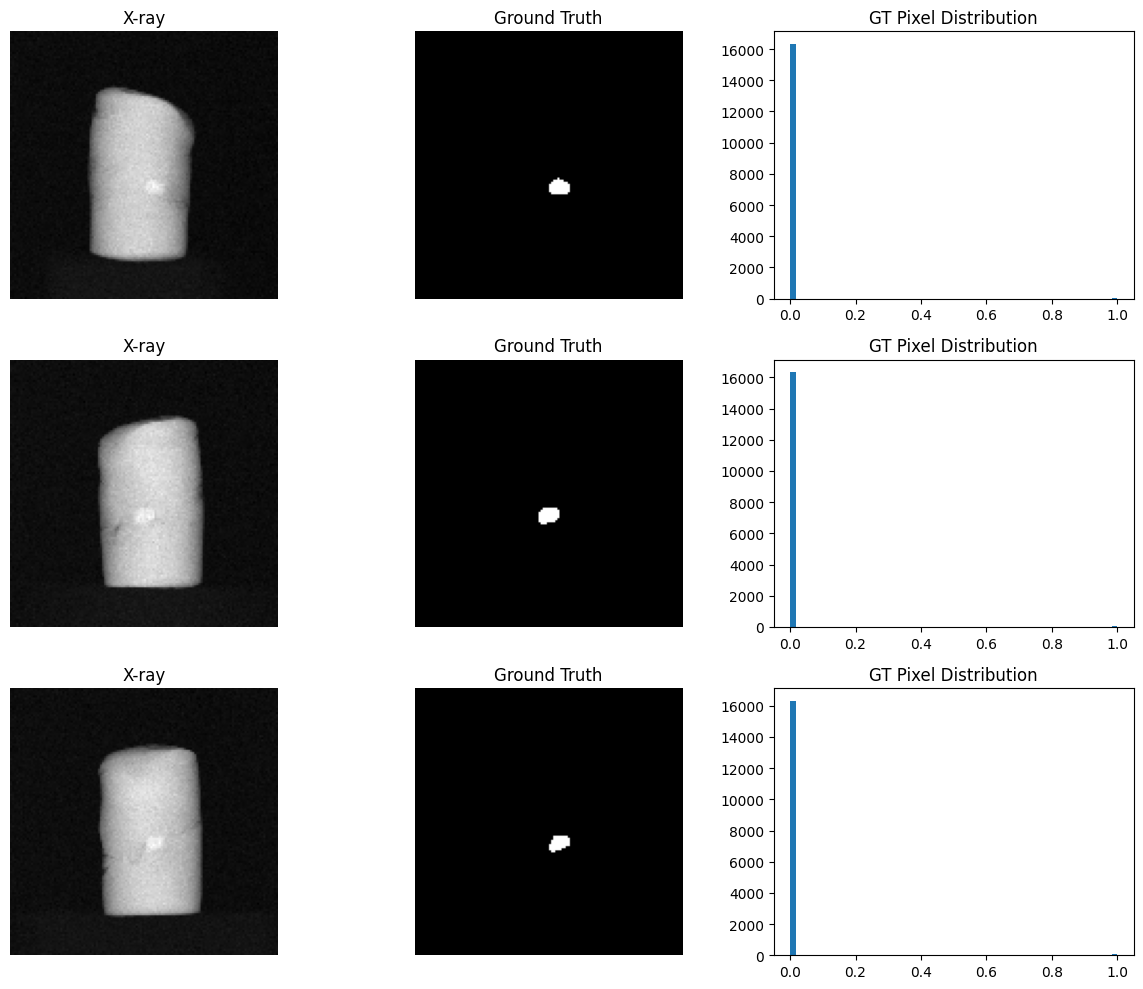

In [56]:
import matplotlib.pyplot as plt
import numpy as np
import tifffile

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for i, (raw_path, gt_path) in enumerate(valid_pairs[:3]):

    raw = np.squeeze(tifffile.imread(raw_path))
    gt = np.squeeze(tifffile.imread(gt_path))

    print(f"\n샘플 {i+1}: {raw_path.name}")
    print("GT min/max:", np.min(gt), np.max(gt))
    print("GT percentiles:",
          np.percentile(gt, [0, 25, 50, 75, 95, 99, 100]))

    axes[i, 0].imshow(raw, cmap="gray")
    axes[i, 0].set_title("X-ray")

    axes[i, 1].imshow(gt, cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].hist(gt.ravel(), bins=60)
    axes[i, 2].set_title("GT Pixel Distribution")

    for ax in axes[i, :2]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [57]:
import cv2 #9
import numpy as np
import tifffile
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 마스크 추출 설정
MIN_AREA = 2
MIN_SIDE = 2

def make_stone_mask(gt):
    gt = np.squeeze(gt).astype(np.float32)

    assert gt.ndim == 2, "GT가 2차원 이미지가 아닙니다."
    assert np.isfinite(gt).all(), "GT에 비정상 값이 있습니다."

    # 가장 많이 나타나는 값에 가까운 값을 배경으로 간주
    values, counts = np.unique(gt, return_counts=True)
    background = values[np.argmax(counts)]

    diff = np.abs(gt - background)

    if diff.max() == 0:
        return np.zeros(gt.shape, dtype=np.uint8)

    # 픽셀 차이를 0~255로 변환
    normalized = np.clip(
        diff / diff.max() * 255,
        0, 255
    ).astype(np.uint8)

    # 차이가 있는 영역을 Otsu 임계값으로 구분
    _, mask = cv2.threshold(
        normalized,
        0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    return mask


def mask_to_boxes(mask):
    num_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    boxes = []

    for i in range(1, num_labels):
        x, y, w, h, area = stats[i]

        if area < MIN_AREA:
            continue

        if w < MIN_SIDE or h < MIN_SIDE:
            continue

        boxes.append((x, y, x + w, y + h))

    return boxes

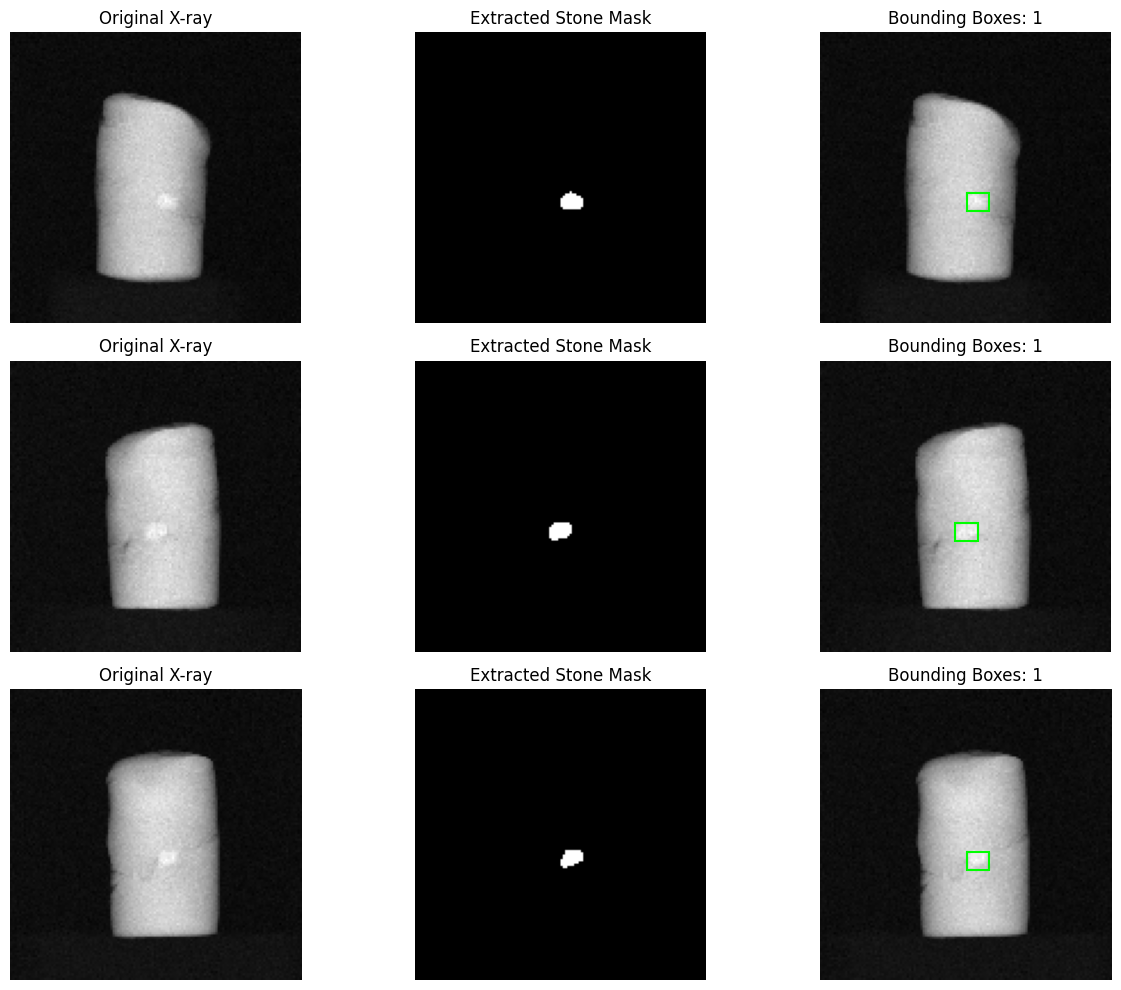

In [59]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10)) #9-1

for i, (raw_path, gt_path) in enumerate(valid_pairs[:3]):

    raw = np.squeeze(tifffile.imread(raw_path))
    gt = np.squeeze(tifffile.imread(gt_path))

    mask = make_stone_mask(gt)
    boxes = mask_to_boxes(mask)

    axes[i, 0].imshow(raw, cmap="gray")
    axes[i, 0].set_title("Original X-ray")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Extracted Stone Mask")

    axes[i, 2].imshow(raw, cmap="gray")

    for x1, y1, x2, y2 in boxes:
        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=1.5,
            edgecolor="lime",
            facecolor="none"
        )
        axes[i, 2].add_patch(rect)

    axes[i, 2].set_title(f"Bounding Boxes: {len(boxes)}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [60]:
from pathlib import Path #10
from collections import defaultdict
from PIL import Image
import numpy as np
import tifffile
import random
import shutil
import re

YOLO_DIR = Path("/content/ClayXray/yolo_dataset")

random.seed(42)

# 이전에 만든 변환 데이터셋만 정리
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)

# Instance별 그룹
groups = defaultdict(list)

for raw_path, gt_path in valid_pairs:
    m = re.search(r"Instance(\d+)", str(raw_path))

    if not m:
        raise ValueError(f"Instance 번호를 찾을 수 없습니다: {raw_path}")

    groups[int(m.group(1))].append((raw_path, gt_path))

instance_ids = sorted(groups)
random.shuffle(instance_ids)

assert len(instance_ids) >= 5, "서로 다른 점토 샘플이 최소 5개 필요합니다."

n_train = int(len(instance_ids) * 0.6)
n_val = int(len(instance_ids) * 0.2)

train_ids = instance_ids[:n_train]
val_ids = instance_ids[n_train:n_train+n_val]
test_ids = instance_ids[n_train+n_val:]

splits = {
    "train": train_ids,
    "val": val_ids,
    "test": test_ids
}

print("Train Instance:", train_ids)
print("Val Instance:", val_ids)
print("Test Instance:", test_ids)
def normalize_xray(img):
    img = np.squeeze(img).astype(np.float32)

    low, high = np.percentile(img, [1, 99])

    if high <= low:
        return np.zeros(img.shape, dtype=np.uint8)

    result = (img - low) / (high - low)
    result = np.clip(result * 255, 0, 255)

    return result.astype(np.uint8)


def save_split(split, ids):
    img_dir = YOLO_DIR / "images" / split
    lbl_dir = YOLO_DIR / "labels" / split

    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)

    total_images = 0
    total_boxes = 0
    empty_images = 0

    for instance_id in ids:
        for raw_path, gt_path in groups[instance_id]:

            raw = np.squeeze(tifffile.imread(raw_path))
            gt = np.squeeze(tifffile.imread(gt_path))

            if raw.shape != gt.shape:
                raise ValueError(
                    f"이미지 크기 불일치: {raw_path.name}"
                )

            H, W = raw.shape

            # 이미지 정규화
            image_8bit = normalize_xray(raw)

            name = f"instance{instance_id:03d}_{raw_path.stem}"

            Image.fromarray(image_8bit).save(
                img_dir / f"{name}.png"
            )

            mask = make_stone_mask(gt)
            boxes = mask_to_boxes(mask)

            lines = []

            for x1, y1, x2, y2 in boxes:

                xc = ((x1 + x2) / 2) / W
                yc = ((y1 + y2) / 2) / H
                bw = (x2 - x1) / W
                bh = (y2 - y1) / H

                lines.append(
                    f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
                )

            (lbl_dir / f"{name}.txt").write_text(
                "\n".join(lines) + "\n"
            )

            total_images += 1
            total_boxes += len(lines)

            if not lines:
                empty_images += 1

    print(
        f"{split}: {total_images} images, "
        f"{total_boxes} boxes, "
        f"{empty_images} empty labels"
    )


for split, ids in splits.items():
    save_split(split, ids)

print("YOLO 데이터셋 생성 완료!")

Train Instance: [8, 4, 3, 9, 6, 7]
Val Instance: [10, 5]
Test Instance: [1, 2]
train: 120 images, 154 boxes, 20 empty labels
val: 40 images, 40 boxes, 0 empty labels
test: 40 images, 40 boxes, 0 empty labels
YOLO 데이터셋 생성 완료!


In [61]:
import yaml #11
from pathlib import Path

YOLO_DIR = Path("/content/ClayXray/yolo_dataset")

data = {
    "path": str(YOLO_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": {0: "stone"}
}

DATA_YAML = YOLO_DIR / "data.yaml"

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("data.yaml 생성 완료:", DATA_YAML)

for split in ["train", "val", "test"]:
    imgs = list((YOLO_DIR / "images" / split).glob("*.png"))
    labels = list((YOLO_DIR / "labels" / split).glob("*.txt"))

    print(f"{split}: {len(imgs)} images / {len(labels)} labels")

    assert len(imgs) == len(labels)
    assert imgs, f"{split} 이미지가 없습니다."

data.yaml 생성 완료: /content/ClayXray/yolo_dataset/data.yaml
train: 120 images / 120 labels
val: 40 images / 40 labels
test: 40 images / 40 labels


In [62]:
%pip install -q ultralytics

In [65]:
import torch
from ultralytics import YOLO

assert torch.cuda.is_available(), "T4 GPU를 활성화하세요."

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=30,
    imgsz=640,
    batch=8,
    workers=0,
    cache=False,
    device=0,
    patience=10,
    project="/content/ClayXray/runs",
    name="yolov8n_stone",
    exist_ok=True,
    plots=True
)

print("학습 완료!")

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ClayXray/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_stone, nbs=64, nms=None, opset=None, optim

In [66]:
from ultralytics import YOLO

best_path = (
    "/content/ClayXray/runs/"
    "yolov8n_stone/weights/best.pt"
)

model = YOLO(best_path)

metrics = model.val(
    data=str(DATA_YAML),
    split="val"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 533.3±150.1 MB/s, size: 9.2 KB)
val: Scanning /content/ClayXray/yolo_dataset/labels/val.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 12.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.6it/s 1.8s
                   all         40         40      0.772      0.725        0.8      0.296
Speed: 8.1ms preprocess, 13.5ms inference, 0.0ms loss, 3.8ms postprocess per image
Results saved to /content/runs/detect/val
Precision: 0.7718697202052226
Recall: 0.725
mAP50: 0.8001848227006987
mAP50-95: 0.2958814248782041


In [58]:
from pathlib import Path
from PIL import Image
from IPython.display import display
import random

val_images = list(
    (YOLO_DIR / "images/val").glob("*.png")
)

random.seed(42)

for image_path in random.sample(
    val_images, min(4, len(val_images))
):

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.15,
        verbose=False
    )[0]

    print(image_path.name)

    display(
        Image.fromarray(
            result.plot()[..., ::-1]
        )
    )